<a href="https://colab.research.google.com/github/Pathikrit003/Cervical-Cancer-/blob/main/train_eva02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install timm kagglehub

In [ ]:
import os

SAVE_TO_DRIVE = True
DRIVE_DIR = "/content/drive/MyDrive/sipakmed_outputs"

if SAVE_TO_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        os.makedirs(DRIVE_DIR, exist_ok=True)
        print("Drive ready:", DRIVE_DIR)
    except Exception as e:
        print(f"Drive not available ({e}). Results will stay in the local folder only.")
        SAVE_TO_DRIVE = False

Mounted at /content/drive
Drive ready: /content/drive/MyDrive/sipakmed_outputs


In [ ]:
import random
import shutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torch.amp import autocast, GradScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

import timm
from timm.data.mixup import Mixup
from timm.loss import SoftTargetCrossEntropy
import kagglehub

warnings.filterwarnings("ignore")

In [ ]:
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

SEED = 42
seed_everything(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUTPUT_DIR = "./sipakmed_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

ACTIVE_BACKBONE = 'eva02'      # 'eva02' | 'beitv2' | 'convnextv2'

IMG_SIZE = 224
BATCH_SIZE = 16
NUM_EPOCHS = 25
WARMUP_EPOCHS = 2
INIT_LR = 3e-5
WEIGHT_DECAY = 0.05
NUM_WORKERS = 2

MIXUP_ALPHA = 0.8
CUTMIX_ALPHA = 1.0
MIXUP_PROB = 0.5
MIXUP_OFF_LAST_EPOCHS = 3
LABEL_SMOOTHING = 0.1
CONTRASTIVE_LOSS_WEIGHT = 0.1

CLASS_MAP = {
    'dyskeratotic': 0,
    'koilocytotic': 1,
    'metaplastic': 2,
    'parabasal': 3,
    'superficial-intermediate': 4,
    'superficial': 4,
    'intermediate': 4
}
CLASS_NAMES = ['Dyskeratotic', 'Koilocytotic', 'Metaplastic', 'Parabasal', 'Superficial-Intermediate']
NUM_CLASSES = 5

print(f"Running on: {DEVICE} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")
print(f"Backbone: {ACTIVE_BACKBONE.upper()}")

Running on: cuda (Tesla T4)
Backbone: EVA02


In [ ]:
print("Downloading SIPaKMeD dataset via kagglehub...")
dataset_dir = kagglehub.dataset_download("prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed")
print(f"Dataset downloaded to: {dataset_dir}")

records = []
for root, dirs, files in os.walk(dataset_dir):
    rel_path = os.path.relpath(root, dataset_dir).lower()
    if 'cropped' not in rel_path:
        continue
    matched = None
    for k, v in CLASS_MAP.items():
        if k in rel_path:
            matched = v
            break
    if matched is not None:
        for f in files:
            if f.lower().endswith(('.bmp', '.jpg', '.jpeg', '.png')):
                records.append({'path': os.path.join(root, f), 'label': matched})

if len(records) == 0:
    print("No images found in 'CROPPED' folders. Folder layout of the download:")
    for root, dirs, files in list(os.walk(dataset_dir))[:15]:
        print("  ", os.path.relpath(root, dataset_dir), f"({len(files)} files)")
    raise RuntimeError("Check the folder names above and adjust the 'cropped' filter.")

df = pd.DataFrame(records).drop_duplicates(subset=['path'])
df['rel'] = df['path'].apply(lambda p: os.path.relpath(p, dataset_dir))
df = df.sort_values('rel').drop(columns='rel').reset_index(drop=True)

print(f"Total single-cell images found: {len(df)}  (expected about 4049)")
print(df['label'].value_counts().sort_index().rename(index=dict(enumerate(CLASS_NAMES))))

Using Colab cache for faster access to the 'cervical-cancer-largest-dataset-sipakmed' dataset.
Dataset downloaded to: /kaggle/input/cervical-cancer-largest-dataset-sipakmed
Total single-cell images found: 4049  (expected about 4049)
label
Dyskeratotic                813
Koilocytotic                825
Metaplastic                 793
Parabasal                   787
Superficial-Intermediate    831
Name: count, dtype: int64


In [ ]:
train_df, test_df = train_test_split(df, test_size=0.20, stratify=df['label'], random_state=SEED)
train_df, val_df = train_test_split(train_df, test_size=0.15, stratify=train_df['label'], random_state=SEED)

print(f"Data split: Train={len(train_df)}, Val={len(val_df)}, Test={len(test_df)}")

Data split: Train=2753, Val=486, Test=810


In [ ]:
class TwoRegionRandomErasing:
    def __init__(self, p=0.5, scale=(0.02, 0.33), ratio=(0.3, 3.3), value='random'):
        self.eraser = transforms.RandomErasing(p=1.0, scale=scale, ratio=ratio, value=value)
        self.p = p

    def __call__(self, img):
        if random.random() < self.p:
            img = self.eraser(img)
        if random.random() < self.p:
            img = self.eraser(img)
        return img

train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(25),
    transforms.RandomAffine(0, scale=(0.75, 1.25)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    TwoRegionRandomErasing(p=0.5, value='random')
])

eval_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [ ]:
class SIPaKMeDDataset(Dataset):
    def __init__(self, data_df, transform=None):
        self.df = data_df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.iloc[idx]['path']
        lbl = int(self.df.iloc[idx]['label'])
        img = Image.open(img_path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, lbl

train_loader = DataLoader(SIPaKMeDDataset(train_df, train_transforms), batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
val_loader = DataLoader(SIPaKMeDDataset(val_df, eval_transforms), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(SIPaKMeDDataset(test_df, eval_transforms), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

mixup_fn = Mixup(
    mixup_alpha=MIXUP_ALPHA,
    cutmix_alpha=CUTMIX_ALPHA,
    prob=1.0,
    label_smoothing=LABEL_SMOOTHING,
    num_classes=NUM_CLASSES
)

def smooth_one_hot(labels, num_classes, smoothing):
    off_value = smoothing / num_classes
    on_value = 1.0 - smoothing + off_value
    targets = torch.full((labels.size(0), num_classes), off_value, device=labels.device)
    targets.scatter_(1, labels.view(-1, 1), on_value)
    return targets

In [ ]:
class BenchmarkModel(nn.Module):
    def __init__(self, backbone_type='eva02', num_classes=5, pretrained=True):
        super().__init__()
        self.backbone_type = backbone_type

        if backbone_type == 'eva02':
            self.backbone = timm.create_model('eva02_large_patch14_224', pretrained=pretrained)
            self.backbone.head = nn.Identity()
            backbone_dim = self.backbone.embed_dim
        elif backbone_type == 'beitv2':
            self.backbone = timm.create_model('beitv2_large_patch16_224', pretrained=pretrained)
            self.backbone.head = nn.Identity()
            backbone_dim = self.backbone.embed_dim
        elif backbone_type == 'convnextv2':
            self.backbone = timm.create_model('convnextv2_large.fcmae_ft_in1k', pretrained=pretrained)
            self.backbone.head = nn.Identity()
            backbone_dim = self.backbone.num_features
        else:
            raise ValueError(f"Unknown backbone: {backbone_type}")

        self.head = nn.Linear(backbone_dim, num_classes)
        self.contrastive_head = nn.Sequential(
            nn.LayerNorm(backbone_dim),
            nn.Linear(backbone_dim, 128)
        )

    def forward(self, x):
        features = self.backbone.forward_features(x)
        if self.backbone_type in ['eva02', 'beitv2']:
            pooled_output = features.mean(dim=1)       # transformers: average over tokens
        else:
            pooled_output = features.mean(dim=[2, 3])  # ConvNeXt: average over height/width

        logits = self.head(pooled_output)
        contrastive_features = self.contrastive_head(pooled_output)
        return logits, F.normalize(contrastive_features, dim=1)

model = BenchmarkModel(backbone_type=ACTIVE_BACKBONE, num_classes=NUM_CLASSES, pretrained=True).to(DEVICE)
print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M")

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.21GB            

model.safetensors: downloading bytes:           |  0.00B            

Parameters: 303.4M


In [ ]:
class SupConLoss(nn.Module):
    def __init__(self, temperature=0.07):
        super().__init__()
        self.temperature = temperature

    def forward(self, features, labels):
        features = features.float()
        batch_size = features.shape[0]
        labels = labels.contiguous().view(-1, 1)
        mask = torch.eq(labels, labels.T).float().to(features.device)

        anchor_dot_contrast = torch.div(torch.matmul(features, features.T), self.temperature)
        logits_max, _ = torch.max(anchor_dot_contrast, dim=1, keepdim=True)
        logits = anchor_dot_contrast - logits_max.detach()

        logits_mask = torch.scatter(
            torch.ones_like(mask), 1,
            torch.arange(batch_size).view(-1, 1).to(features.device), 0
        )
        mask = mask * logits_mask
        exp_logits = torch.exp(logits) * logits_mask
        log_prob = logits - torch.log(exp_logits.sum(1, keepdim=True) + 1e-6)

        mask_sum = mask.sum(1)
        mean_log_prob_pos = (mask * log_prob).sum(1) / (mask_sum + 1e-6)
        return -mean_log_prob_pos.mean()

classification_loss_fn = SoftTargetCrossEntropy().to(DEVICE)
contrastive_loss_fn = SupConLoss().to(DEVICE)

In [ ]:
optimizer = optim.AdamW(model.parameters(), lr=INIT_LR, weight_decay=WEIGHT_DECAY)

warmup = optim.lr_scheduler.LinearLR(optimizer, start_factor=0.1, total_iters=WARMUP_EPOCHS)
cosine = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS - WARMUP_EPOCHS, eta_min=1e-7)
scheduler = optim.lr_scheduler.SequentialLR(optimizer, schedulers=[warmup, cosine], milestones=[WARMUP_EPOCHS])

scaler = GradScaler('cuda')   # mixed precision: faster and uses less GPU memory

In [ ]:
best_val_acc = 0.0
best_epoch = 0
train_acc_at_best = 0.0
best_model_path = os.path.join(OUTPUT_DIR, f"best_{ACTIVE_BACKBONE}_sipakmed.pth")
history = []

print(f"--- Starting Training ({ACTIVE_BACKBONE.upper()}) ---")

for epoch in range(NUM_EPOCHS):
    model.train()
    total_train_loss = 0.0
    clean_correct, clean_total = 0, 0
    mixup_active = epoch < NUM_EPOCHS - MIXUP_OFF_LAST_EPOCHS

    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]")
    for images, labels in pbar:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        use_mix = mixup_active and (random.random() < MIXUP_PROB)

        if use_mix:
            images, targets = mixup_fn(images, labels)
        else:
            targets = smooth_one_hot(labels, NUM_CLASSES, LABEL_SMOOTHING)

        optimizer.zero_grad()
        with autocast('cuda'):
            logits, features = model(images)
            loss = classification_loss_fn(logits, targets)
            if not use_mix and CONTRASTIVE_LOSS_WEIGHT > 0:
                loss = loss + CONTRASTIVE_LOSS_WEIGHT * contrastive_loss_fn(features, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_train_loss += loss.item()
        if not use_mix:
            clean_total += labels.size(0)
            clean_correct += (logits.argmax(1) == labels).sum().item()
        pbar.set_postfix(loss=f"{loss.item():.4f}")

    scheduler.step()
    train_acc = (clean_correct / clean_total) * 100 if clean_total > 0 else float('nan')
    avg_train_loss = total_train_loss / len(train_loader)

    # ---- validation ----
    model.eval()
    val_correct, val_total = 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            with autocast('cuda'):
                logits, _ = model(images)
            val_total += labels.size(0)
            val_correct += (logits.argmax(1) == labels).sum().item()

    val_acc = (val_correct / val_total) * 100
    lr_now = optimizer.param_groups[0]['lr']
    history.append({'epoch': epoch + 1, 'train_loss': avg_train_loss, 'train_acc': train_acc, 'val_acc': val_acc, 'lr': lr_now})
    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | Loss: {avg_train_loss:.4f} | Train Acc (clean): {train_acc:.2f}% "
          f"| Val Acc: {val_acc:.2f}% | LR: {lr_now:.2e} | Mixup: {'on' if mixup_active else 'off'}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch + 1
        train_acc_at_best = train_acc
        torch.save(model.state_dict(), best_model_path)
        print(f"  -> Saved best model (Val Acc: {best_val_acc:.2f}%)")

pd.DataFrame(history).to_csv(os.path.join(OUTPUT_DIR, f"{ACTIVE_BACKBONE}_history.csv"), index=False)
print(f"\nDone. Best epoch: {best_epoch} (Val Acc {best_val_acc:.2f}%)")

--- Starting Training (EVA02) ---


Epoch 1/25 [Train]:   0%|          | 0/172 [00:00<?, ?it/s]

Epoch 01/25 | Loss: 1.1861 | Train Acc (clean): 77.83% | Val Acc: 88.89% | LR: 1.65e-05 | Mixup: on
  -> Saved best model (Val Acc: 88.89%)


Epoch 2/25 [Train]:   0%|          | 0/172 [00:00<?, ?it/s]

Epoch 02/25 | Loss: 0.9706 | Train Acc (clean): 88.13% | Val Acc: 94.65% | LR: 3.00e-05 | Mixup: on
  -> Saved best model (Val Acc: 94.65%)


Epoch 3/25 [Train]:   0%|          | 0/172 [00:00<?, ?it/s]

... (53 outputs left out)

Epoch 24/25 | Loss: 0.4883 | Train Acc (clean): 100.00% | Val Acc: 98.77% | LR: 2.39e-07 | Mixup: off


Epoch 25/25 [Train]:   0%|          | 0/172 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78d54642a160><function _MultiProcessingDataLoaderIter.__del__ at 0x78d54642a160>

Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()    
self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers

      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only te

Epoch 25/25 | Loss: 0.4905 | Train Acc (clean): 99.89% | Val Acc: 98.77% | LR: 1.00e-07 | Mixup: off

Done. Best epoch: 20 (Val Acc 99.18%)


In [ ]:
del model
torch.cuda.empty_cache()

eval_model = BenchmarkModel(backbone_type=ACTIVE_BACKBONE, num_classes=NUM_CLASSES, pretrained=False)
eval_model.load_state_dict(torch.load(best_model_path, map_location=DEVICE))
eval_model.to(DEVICE)
eval_model.eval()

def predict(loader, desc):
    y_true, y_prob = [], []
    with torch.no_grad():
        for images, labels in tqdm(loader, desc=desc):
            images = images.to(DEVICE)
            with autocast('cuda'):
                logits, _ = eval_model(images)
            y_true.extend(labels.numpy())
            y_prob.extend(logits.float().softmax(1).cpu().numpy())
    return np.array(y_true), np.array(y_prob)

val_true, val_prob = predict(val_loader, "Predicting Val Set")
y_true, y_prob = predict(test_loader, "Evaluating Test Set")
y_pred = y_prob.argmax(1)

np.save(os.path.join(OUTPUT_DIR, f"{ACTIVE_BACKBONE}_val_probs.npy"), val_prob)
np.save(os.path.join(OUTPUT_DIR, f"{ACTIVE_BACKBONE}_test_probs.npy"), y_prob)
np.save(os.path.join(OUTPUT_DIR, "val_labels.npy"), val_true)
np.save(os.path.join(OUTPUT_DIR, "test_labels.npy"), y_true)
print("Saved probability files.")

Predicting Val Set:   0%|          | 0/31 [00:00<?, ?it/s]

Evaluating Test Set:   0%|          | 0/51 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78d54642a160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78d54642a160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Saved probability files.


Model  Best Epoch  Train Acc (%)  Val Acc (%)  Test Acc (%)  Macro Precision  Macro Recall  Macro F1-Score
EVA02          20          99.92        99.18         98.27           0.9829        0.9828          0.9828

Detailed per-class performance:
                          precision    recall  f1-score   support

            Dyskeratotic     0.9877    0.9877    0.9877       163
            Koilocytotic     0.9752    0.9515    0.9632       165
             Metaplastic     0.9750    0.9811    0.9781       159
               Parabasal     1.0000    0.9936    0.9968       157
Superficial-Intermediate     0.9765    1.0000    0.9881       166

                accuracy                         0.9827       810
               macro avg     0.9829    0.9828    0.9828       810
            weighted avg     0.9827    0.9827    0.9827       810



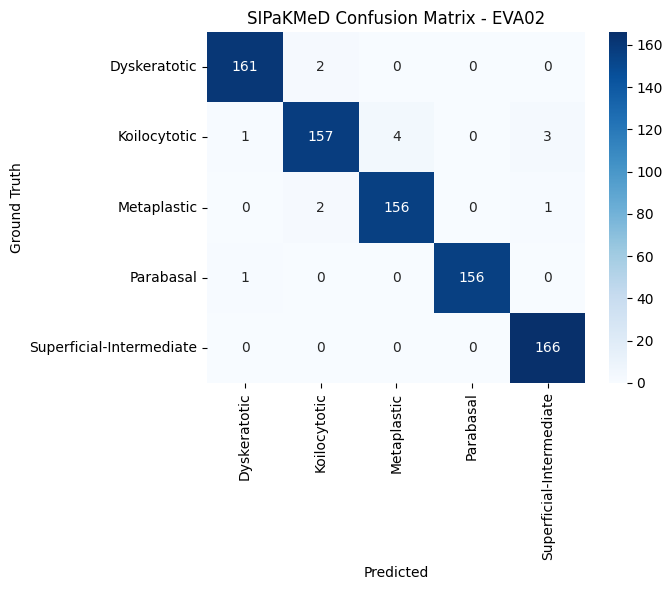

In [ ]:
test_acc = accuracy_score(y_true, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)

summary_table = pd.DataFrame([{
    "Model": ACTIVE_BACKBONE.upper(),
    "Best Epoch": best_epoch,
    "Train Acc (%)": round(train_acc_at_best, 2),
    "Val Acc (%)": round(best_val_acc, 2),
    "Test Acc (%)": round(test_acc * 100, 2),
    "Macro Precision": round(prec, 4),
    "Macro Recall": round(rec, 4),
    "Macro F1-Score": round(f1, 4)
}])
summary_table.to_csv(os.path.join(OUTPUT_DIR, f"{ACTIVE_BACKBONE}_summary.csv"), index=False)

print(summary_table.to_string(index=False))
print("\nDetailed per-class performance:")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title(f"SIPaKMeD Confusion Matrix - {ACTIVE_BACKBONE.upper()}")
plt.xlabel("Predicted")
plt.ylabel("Ground Truth")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f"{ACTIVE_BACKBONE}_confusion_matrix.png"), dpi=300)
plt.show()

In [ ]:
if SAVE_TO_DRIVE:
    try:
        for f in os.listdir(OUTPUT_DIR):
            if f.endswith('.pth'):
                continue
            shutil.copy(os.path.join(OUTPUT_DIR, f), DRIVE_DIR)
        print(f"Results copied to Google Drive: {DRIVE_DIR}")
        print("Files there now:")
        for f in sorted(os.listdir(DRIVE_DIR)):
            print("  ", f)
    except Exception as e:
        print(f"Could not copy to Drive ({e}). Download the files in {OUTPUT_DIR} manually.")
else:
    print("SAVE_TO_DRIVE is off. Download the files in", OUTPUT_DIR)

Results copied to Google Drive: /content/drive/MyDrive/sipakmed_outputs
Files there now:
   eva02_confusion_matrix.png
   eva02_history.csv
   eva02_summary.csv
   eva02_test_probs.npy
   eva02_val_probs.npy
   test_labels.npy
   val_labels.npy
